# Visualize Layer-Averaged Non-Graph Baselines Across Context Lengths

This Visualize notebook loads the cached data produced by `Generate-layer-averaged-non-graph-baselines-across-context-lengths.ipynb` together with the graph-diagnostics cache and compares layer-averaged diagnostics across context lengths for the main numerical input families using Llama-3.2-3B, as presented under **Attention-Only and Hidden-State-Only Non-Graph Baselines** in the appendix. Graph-spectral diagnostics appear on the left and the corresponding non-graph controls on the right.

The top-row control is attention-only: increasing attention Gini indicates more concentrated attention. The lower two controls are hidden-state-only and measure high-frequency energy and effective spectral support in a fixed positional-frequency basis. Matched y-axis scales in the lower two rows compare analogous spectral properties. Shaded bands show standard deviations across realizations.

The included graph-diagnostics cache is copied from the layer-averaged data generated by `Main/Graph-spectral-diagnostics/Generate-layer-averaged-diagnostics-across-context-lengths.ipynb`.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter
from matplotlib.transforms import Bbox

In [ ]:
# Run from this notebook's directory; load both cached datasets from cache/
GRAPH_DATA_PATH = Path("cache") / "all_metrics_averaged_over_layers_vs_context_length.npz"
BASELINE_DATA_PATH = Path("cache") / "baseline_metrics_averaged_over_layers_vs_context_length.npz"


def _scalar_str(data, key):
    return str(np.asarray(data[key]).item())


def _scalar_int(data, key):
    return int(np.asarray(data[key]).item())


# Load graph-diagnostic summary statistics across realizations
with np.load(GRAPH_DATA_PATH, allow_pickle=False) as graph_data:
    graph_input_names = graph_data["input_names"].astype(str)
    graph_context_token_counts = graph_data["context_token_counts"].astype(np.int64)
    graph_run_ids = graph_data["run_ids"].astype(np.int64) if "run_ids" in graph_data.files else None
    graph_num_layers = _scalar_int(graph_data, "num_layers")
    graph_num_ensemble_runs = _scalar_int(graph_data, "num_ensemble_runs")
    graph_model_name = _scalar_str(graph_data, "model_name")

    graph_fiedler_mean = graph_data["fiedler_mean"].astype(float)
    graph_fiedler_std = graph_data["fiedler_std"].astype(float)
    graph_hfer_mean = graph_data["hfer_mean"].astype(float)
    graph_hfer_std = graph_data["hfer_std"].astype(float)
    graph_active_modes_mean = graph_data["active_modes_mean"].astype(float)
    graph_active_modes_std = graph_data["active_modes_std"].astype(float)

# Load the attention-only and hidden-state-only statistics
with np.load(BASELINE_DATA_PATH, allow_pickle=False) as baseline_data:
    baseline_input_names = baseline_data["input_names"].astype(str)
    baseline_context_token_counts = baseline_data["context_token_counts"].astype(np.int64)
    baseline_run_ids = baseline_data["run_ids"].astype(np.int64) if "run_ids" in baseline_data.files else None
    baseline_num_layers = _scalar_int(baseline_data, "num_layers")
    baseline_num_ensemble_runs = _scalar_int(baseline_data, "num_ensemble_runs")
    baseline_model_name = _scalar_str(baseline_data, "model_name")

    positional_active_modes_mean = baseline_data["positional_active_modes_mean"].astype(float)
    positional_active_modes_std = baseline_data["positional_active_modes_std"].astype(float)
    positional_hfer_mean = baseline_data["positional_hfer_mean"].astype(float)
    positional_hfer_std = baseline_data["positional_hfer_std"].astype(float)
    normalized_mean_row_attention_gini_mean = baseline_data[
        "normalized_mean_row_attention_gini_mean"
    ].astype(float)
    normalized_mean_row_attention_gini_std = baseline_data[
        "normalized_mean_row_attention_gini_std"
    ].astype(float)

# Require aligned input families, contexts, realizations, model, and layer count
if not np.array_equal(graph_input_names, baseline_input_names):
    raise ValueError("Graph and baseline caches have different input_names.")
if not np.array_equal(graph_context_token_counts, baseline_context_token_counts):
    raise ValueError("Graph and baseline caches have different context_token_counts.")
if graph_run_ids is not None and baseline_run_ids is not None and not np.array_equal(graph_run_ids, baseline_run_ids):
    raise ValueError("Graph and baseline caches have different run_ids.")
if graph_model_name != baseline_model_name:
    raise ValueError("Graph and baseline caches have different model_name values.")
if graph_num_layers != baseline_num_layers:
    raise ValueError("Graph and baseline caches have different num_layers values.")

input_names = graph_input_names
context_token_counts = graph_context_token_counts
num_layers = graph_num_layers
num_ensemble_runs = baseline_num_ensemble_runs
model_name = graph_model_name

# Validate one finite mean and standard deviation per input family and context length
expected_shape = (len(input_names), len(context_token_counts))
for key, value in {
    "graph_fiedler_mean": graph_fiedler_mean,
    "graph_fiedler_std": graph_fiedler_std,
    "graph_hfer_mean": graph_hfer_mean,
    "graph_hfer_std": graph_hfer_std,
    "graph_active_modes_mean": graph_active_modes_mean,
    "graph_active_modes_std": graph_active_modes_std,
    "normalized_mean_row_attention_gini_mean": normalized_mean_row_attention_gini_mean,
    "normalized_mean_row_attention_gini_std": normalized_mean_row_attention_gini_std,
    "positional_hfer_mean": positional_hfer_mean,
    "positional_hfer_std": positional_hfer_std,
    "positional_active_modes_mean": positional_active_modes_mean,
    "positional_active_modes_std": positional_active_modes_std,
}.items():
    if value.shape != expected_shape:
        raise ValueError(f"{key} shape {value.shape}, expected {expected_shape}.")
    if not np.isfinite(value).all():
        raise ValueError(f"{key} contains nonfinite values.")


In [ ]:
def _diagnostic_line_style(data_name):
    # Use consistent styles across graph diagnostics and non-graph controls
    if data_name in {"Constant 500", "Constant sampled"}:
        style = dict(color="#D8D7E6", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.2":
        style = dict(color="#C6D9F1", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5":
        style = dict(color="#A9C8EA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.55":
        style = dict(color="#83B2DC", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.566":
        style = dict(color="#5F98CA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5692":
        style = dict(color="#3E78B2", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.5698":
        style = dict(color="#24518A", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.9":
        style = dict(color="#E68169", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Logistic r=4.0":
        style = dict(color="#C8525E", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Lorenz":
        style = dict(color="#98334F", linestyle="-.", marker="o", linewidth=2.8)
    else:
        style = dict(color="#4C72B0", linestyle="-", marker="o", linewidth=2.0)

    if data_name == "Lorenz":
        style["zorder"] = 5
    elif data_name in {"Logistic r=3.9", "Logistic r=4.0"}:
        style["zorder"] = 4
    else:
        style["zorder"] = 2

    style["markersize"] = 4.0
    return style


def _plot_context_metric(ax, mean, std):
    # Plot means with one-standard-deviation bands across realizations
    x = context_token_counts.astype(float)
    for input_idx, data_name in enumerate(input_names):
        y = mean[input_idx].astype(float)
        band = std[input_idx].astype(float)
        style = _diagnostic_line_style(str(data_name))
        zorder = style.get("zorder", 2)
        ax.plot(
            x,
            y,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.1,
            marker=style["marker"],
            markersize=1.45,
            zorder=zorder,
        )
        ax.fill_between(
            x,
            y - band,
            y + band,
            color=style["color"],
            alpha=0.15,
            linewidth=0,
            zorder=max(zorder - 0.5, 0),
        )


def _format_context_axis(ax, ylabel):
    ax.set_ylabel(ylabel, labelpad=1.5, fontsize=5.6)
    ax.set_xlim(0, 2080)
    ax.set_xticks([0, 1000, 2000])
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)


def _set_padded_ylim(ax, mean, std):
    low = float(np.nanmin(mean - std))
    high = float(np.nanmax(mean + std))
    span = high - low
    pad = 0.06 * span if span > 0 else 0.1 * max(abs(high), 1.0)
    lower = max(0.0, low - pad) if low >= 0 else low - pad
    ax.set_ylim(lower, high + pad)


# Order the shared legend from constant and periodic inputs to chaotic inputs
complexity_legend_order = [
    "Constant sampled",
    "Logistic r=3.2",
    "Logistic r=3.5",
    "Logistic r=3.55",
    "Logistic r=3.566",
    "Logistic r=3.5692",
    "Logistic r=3.5698",
    "Logistic r=3.9",
    "Logistic r=4.0",
    "Lorenz",
]


def _complexity_legend_rows(data_name):
    label_map = {
        "Constant sampled": ("Constant", ""),
        "Logistic r=3.2": ("Period 2", ""),
        "Logistic r=3.5": ("Period 4", ""),
        "Logistic r=3.55": ("Period 8", ""),
        "Logistic r=3.566": ("Period 16", ""),
        "Logistic r=3.5692": ("Period 32", ""),
        "Logistic r=3.5698": ("Period 64", ""),
        "Logistic r=3.9": ("r=3.9", ""),
        "Logistic r=4.0": ("r=4.0", ""),
        "Lorenz": ("Lorenz", ""),
    }
    return label_map.get(str(data_name), (str(data_name), ""))


def _add_complexity_strip_legend(fig):
    ordered_names = [name for name in complexity_legend_order if name in set(input_names.astype(str))]
    items_per_row = int(np.ceil(len(ordered_names) / 2))
    ax_leg = fig.add_axes([0.090, 0.070, 0.895, 0.145])
    ax_leg.set_xlim(-0.45, items_per_row - 0.55)
    ax_leg.set_ylim(0.0, 1.0)
    ax_leg.axis("off")

    spacing_scale = 0.92
    swatch_half_width = 0.198
    swatch_height = 0.0855
    legend_center = 0.5 * (items_per_row - 1)

    def _legend_x(raw_x):
        return legend_center + spacing_scale * (float(raw_x) - legend_center)

    for idx, data_name in enumerate(ordered_names):
        row_idx = idx // items_per_row
        col_idx = idx % items_per_row
        legend_x = _legend_x(col_idx)
        line_y = 0.770 if row_idx == 0 else 0.450
        text_y = line_y - 0.160
        style = _diagnostic_line_style(str(data_name))
        ax_leg.add_patch(
            Rectangle(
                (legend_x - swatch_half_width, line_y - 0.5 * swatch_height),
                2.0 * swatch_half_width,
                swatch_height,
                facecolor=style["color"],
                edgecolor="none",
                alpha=0.34,
            )
        )
        ax_leg.plot(
            [legend_x - swatch_half_width, legend_x + swatch_half_width],
            [line_y, line_y],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=0.95,
            solid_capstyle="round",
        )
        ax_leg.plot(legend_x, line_y, marker=style["marker"], markersize=1.55, color=style["color"])
        top_label, bottom_label = _complexity_legend_rows(data_name)
        ax_leg.text(legend_x, text_y, top_label, ha="center", va="center", fontsize=4.10)
        if bottom_label:
            ax_leg.text(legend_x, text_y - 0.085, bottom_label, ha="center", va="center", fontsize=4.10)

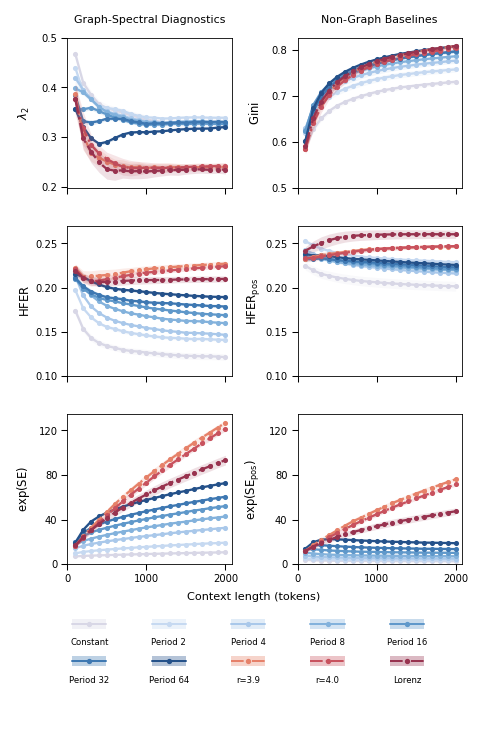

In [ ]:
# Save the comparison PDF
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
COMBINED_FIGURE_PATH = FIGURE_DIR / "non-graph-baseline-comparison.pdf"

# Pair graph diagnostics (left) with attention Gini, positional HFER, and positional support (right)
panel_specs = [
    (
        graph_fiedler_mean,
        graph_fiedler_std,
        r"$\lambda_2$",
        normalized_mean_row_attention_gini_mean,
        normalized_mean_row_attention_gini_std,
        r"$\mathrm{Gini}$",
    ),
    (
        graph_hfer_mean,
        graph_hfer_std,
        r"$\mathrm{HFER}$",
        positional_hfer_mean,
        positional_hfer_std,
        r"$\mathrm{HFER}_{\mathrm{pos}}$",
    ),
    (
        graph_active_modes_mean,
        graph_active_modes_std,
        r"$\exp(\mathrm{SE})$",
        positional_active_modes_mean,
        positional_active_modes_std,
        r"$\exp(\mathrm{SE}_{\mathrm{pos}})$",
    ),
]

with plt.rc_context({
    "font.size": 7.6,
    "axes.labelsize": 5.4,
    "axes.titlesize": 6.0,
    "xtick.labelsize": 4.8,
    "ytick.labelsize": 4.8,
    "axes.linewidth": 0.4,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig, axes = plt.subplots(3, 2, figsize=(3.15, 5.40), dpi=150, sharex=True)
    fig.subplots_adjust(left=0.155, right=0.990, top=0.905, bottom=0.255, hspace=0.25, wspace=0.40)

    for row_idx, (left_mean, left_std, left_ylabel, right_mean, right_std, right_ylabel) in enumerate(panel_specs):
        _plot_context_metric(axes[row_idx, 0], left_mean, left_std)
        _plot_context_metric(axes[row_idx, 1], right_mean, right_std)
        _format_context_axis(axes[row_idx, 0], left_ylabel)
        _format_context_axis(axes[row_idx, 1], right_ylabel)
        _set_padded_ylim(axes[row_idx, 0], left_mean, left_std)
        _set_padded_ylim(axes[row_idx, 1], right_mean, right_std)

    # Match the lower-row y-axis scales to compare analogous spectral properties
    axes[1, 0].set_ylim(0.10, 0.27)
    axes[1, 1].set_ylim(0.10, 0.27)
    axes[2, 0].set_ylim(0, 135)
    axes[2, 1].set_ylim(0, 135)

    axes[0, 0].set_yticks([0.2, 0.3, 0.4, 0.5])
    axes[0, 1].set_yticks([0.5, 0.6, 0.7, 0.8])
    axes[1, 0].set_yticks([0.1, 0.15, 0.2, 0.25])
    axes[1, 1].set_yticks([0.10, 0.15, 0.20, 0.25])
    axes[2, 0].set_yticks([0, 40, 80, 120])
    axes[2, 1].set_yticks([0, 40, 80, 120])

    for ax in axes.flat:
        ax.tick_params(axis="both", which="major", length=2.8, pad=2.0)
    for ax in axes[:-1, :].flat:
        ax.tick_params(labelbottom=False)

    axes[0, 0].yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    axes[0, 1].yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    axes[1, 0].yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    axes[1, 1].yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    axes[2, 0].yaxis.set_major_formatter(FormatStrFormatter("%.0f"))
    axes[2, 1].yaxis.set_major_formatter(FormatStrFormatter("%.0f"))

    left_header_x = axes[0, 0].get_position().x0 + 0.5 * axes[0, 0].get_position().width
    right_header_x = axes[0, 1].get_position().x0 + 0.5 * axes[0, 1].get_position().width
    fig.text(left_header_x, 0.927, "Graph-Spectral Diagnostics", ha="center", va="center", fontsize=5.25)
    fig.text(right_header_x, 0.927, "Non-Graph Baselines", ha="center", va="center", fontsize=5.25)
    fig.supxlabel("Context length (tokens)", x=0.55, y=0.208, fontsize=5.4)
    fig.align_ylabels(axes[:, 0])
    fig.align_ylabels(axes[:, 1])

    _add_complexity_strip_legend(fig)
    # Preserve the original 300-dpi rendering used to measure the PDF crop
    fig.set_dpi(300)
    fig.canvas.draw()
    tight_bbox = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.01)
    pdf_bbox = Bbox.from_extents(tight_bbox.x0, tight_bbox.y0 + 0.18, tight_bbox.x1, tight_bbox.y1)
    fig.savefig(COMBINED_FIGURE_PATH, format="pdf", bbox_inches=pdf_bbox)
    # Display the figure in the notebook at 150 dpi
    fig.set_dpi(150)
    plt.show()
